# Checks behind the 1 Nov 2026 La Niña outlook: pooling, hindcast skill, peak timing

Companion of `01_year3_drift_sensitivity`, for the same 36-month 1 Nov 2026 start (30 pooled members):

1. **IC-set consistency.** Pooling the clim, obs and NSIDC runs (10 members each) into one 30-member
   ensemble assumes they sample the same forecast distribution. One-way F-test (and Levene's test for equal
   spread) of the DJF means across the three sets, for each winter. All sets share the same drift
   correction and climatology, so the test does not depend on the year-3 drift method.
2. **Hindcast skill.** Niño3.4 anomaly correlation of the Reanalysis (BruteForce) 1 Nov starts (ensemble
   mean, 1981-2018) with HadISST 1.1 for the year-1 (DJF, leads 1-3) and year-2 (DJF, leads 13-15) winters;
   with and without a linear trend, against persistence of the observed October anomaly. A correlation
   over years does not depend on the lead-dependent mean, so it holds for any drift correction.
3. **Peak timing.** When the ensemble mean peaks and when it crosses zero (and −0.5 °C), with the member
   spread; against the 2026 observations so far, the observed strong El Niños and the other 2026 starts.
   This addresses the remark that other models peak earlier.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf

### Run controls

In [2]:
NOTEBOOK = "nov2026_outlook/02_outlook_checks"   # outputs: rc.OUTPUT_ROOT/nov2026_outlook/02_outlook_checks/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"

YEAR, INIT = 2026, 11
NLEAD_REF = rc.NLEAD
NLEAD = rc.start_nlead(YEAR, INIT)
REF_YEARS = (1981, 2018)
CLIM = (1981, 2010)                         # observed climatology and drift starts (as the other notebooks)
POOL = {name: rc.CASES[name]["case_prefix"] for name in rc.POOLED_CASES}
NINO_BOX = rc.NINO_REGIONS["Nino3.4"]
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)
OBS_PRODUCT = "HadISST1.1"
WINTERS = {"2026/27": 1, "2027/28": 13, "2028/29": 25}   # first lead (Dec) of each DJF for a 1 Nov start
YEAR3_METHOD = "adjusted, r = 1"            # year-3 drift for the peak-timing and DJF values (01_year3_drift_sensitivity)
ADJUST_LEADS = 3
STRONG_EVENTS = [1982, 1997, 2015, 2023]    # observed El Niño onset years (peak in the following DJF)
OTHER_STARTS = (2, 5, 8)                    # the other 2026 starts (24 months, rc.hindcast_anomaly)
SMOOTH = 3                                  # running mean (months) for peak and crossing dates (ONI-like)
ALPHA = 0.05

DATA_DIR = rc.output_dir(NOTEBOOK, "data")
plt.rcParams.update({"font.size": 12, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=200))

### Load (the index cache of `01_year3_drift_sensitivity`; built here if missing)

In [3]:
%%time
CACHE = rc.diag_dir("RTENSO2026_pool", "nino_drift",
                    f"nino34_trop_init{INIT:02d}_ref{REF_YEARS[0]}-{REF_YEARS[1]}_y{YEAR}_l{NLEAD}_{OBS_PRODUCT}_v1.nc")
EXPECTED = {"ref_years": f"{REF_YEARS[0]}-{REF_YEARS[1]}", "year": YEAR, "init": INIT, "nlead": NLEAD,
            "pool": ",".join(POOL), "obs": OBS_PRODUCT}


def build_indices():
    ocean = rc.land_fraction() < 0.5
    idx = lambda da: (rc.box_mean(da, NINO_BOX).load(), rc.box_mean(da.where(ocean), TROPICAL_BOX).load())
    rn, rt, years = [], [], []
    for y in range(REF_YEARS[0], REF_YEARS[1] + 1):
        ens = rc.open_hindcast(rc.REFERENCE["case_prefix"], y, INIT, "TS")
        if ens is None:
            continue
        n, t = idx(ens.mean("member"))
        rn.append(n.values), rt.append(t.values), years.append(y)
    fn, ft, members = [], [], []
    for name, prefix in POOL.items():
        ens = rc.open_hindcast(prefix, YEAR, INIT, "TS")
        n, t = idx(ens)
        fn.append(n.values), ft.append(t.values)
        members += [f"{rc.CASES[name]['short']}:{m}" for m in ens["member"].values]
    obs = rc.obs_monthly("TS", years=(REF_YEARS[0], YEAR), mode=derivation_mode, product=OBS_PRODUCT)
    on, ot = idx(obs)
    ds = xr.Dataset(
        {"ref_nino": (("year", "lead"), np.array(rn)), "ref_trop": (("year", "lead"), np.array(rt)),
         "fc_nino": (("member", "flead"), np.concatenate(fn)), "fc_trop": (("member", "flead"), np.concatenate(ft)),
         "obs_nino": ("time", on.values), "obs_trop": ("time", ot.values)},
        coords={"year": years, "lead": np.arange(NLEAD_REF), "member": members, "flead": np.arange(NLEAD),
                "time": [f"{t.year:04d}-{t.month:02d}" for t in obs["time"].to_index()]})
    ds.attrs.update(EXPECTED, units="degC")
    return ds


if derivation_mode != "rebuild" and CACHE.is_file() and all(
        str(load_netcdf(CACHE).attrs.get(k)) == str(v) for k, v in EXPECTED.items()):
    D = load_netcdf(CACHE)
else:
    D = build_indices()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(D, CACHE)

OBS = pd.Series(D["obs_nino"].values, index=pd.PeriodIndex(D["time"].values, freq="M"))
OBS_T = pd.Series(D["obs_trop"].values, index=OBS.index)
MONTH = [(INIT - 1 + L) % 12 + 1 for L in range(NLEAD)]


def month_clim(obs, clim):
    sel = obs[(obs.index.year >= clim[0]) & (obs.index.year <= clim[1])]
    return sel.groupby(sel.index.month).mean()


def target(y, lead):
    return pd.Period(year=y, month=INIT, freq="M") + int(lead)


def series(kind):
    if kind == "Nino3.4":
        return D["ref_nino"], D["fc_nino"], OBS
    return D["ref_nino"] - D["ref_trop"], D["fc_nino"] - D["fc_trop"], OBS - OBS_T


def roni_scale(clim):
    an = OBS - month_clim(OBS, clim).reindex(OBS.index.month).values
    at = OBS_T - month_clim(OBS_T, clim).reindex(OBS_T.index.month).values
    sel = (an.index.year >= clim[0]) & (an.index.year <= clim[1])
    return float(an[sel].rolling(3, center=True).mean().std() / (an - at)[sel].rolling(3, center=True).mean().std())


def forecast_anomaly(kind):
    # pooled members (member, lead): 1981-2010 drift and climatology, year 3 by YEAR3_METHOD
    ref, fc, obs = series(kind)
    years = [y for y in ref["year"].values if CLIM[0] <= y <= CLIM[1]]
    d = np.array([[float(ref.sel(year=y, lead=L)) - obs[target(y, L)] for L in range(NLEAD_REF)] for y in years]).mean(0)
    delta = d[12:] - d[:12]
    delta = np.where(np.arange(12) < ADJUST_LEADS, delta[ADJUST_LEADS:].mean(), delta)
    r = {"hold (r = 0)": 0.0, "adjusted, r = 1": 1.0}[YEAR3_METHOD]
    dext = np.r_[d, d[12:] + r * delta]
    a = fc.values - (month_clim(obs, CLIM).loc[MONTH].values + dext)[None, :]
    return a * roni_scale(CLIM) if kind == "Relative" else a


ANOM = {k: forecast_anomaly(k) for k in ("Nino3.4", "Relative")}
SETS = np.array([m.split(":")[0] for m in D["member"].values])
print(f"{D.sizes['member']} members: " + ", ".join(f"{s} {int((SETS == s).sum())}" for s in dict.fromkeys(SETS)))

30 members: CLIM 10, OBS 10, NSIDC 10
CPU times: user 954 ms, sys: 420 ms, total: 1.37 s
Wall time: 4.84 s


### 1. Can the three IC sets be pooled?

For each winter and index: one-way F-test of the DJF means across clim, obs and NSIDC (H₀: equal means) and
Levene's test (H₀: equal variances). A large p-value means no detectable difference between the sets at 10
members each, which supports pooling; it does not prove the sets are identical.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/02_outlook_checks/figures/fig_nov2026_ic_set_consistency.png


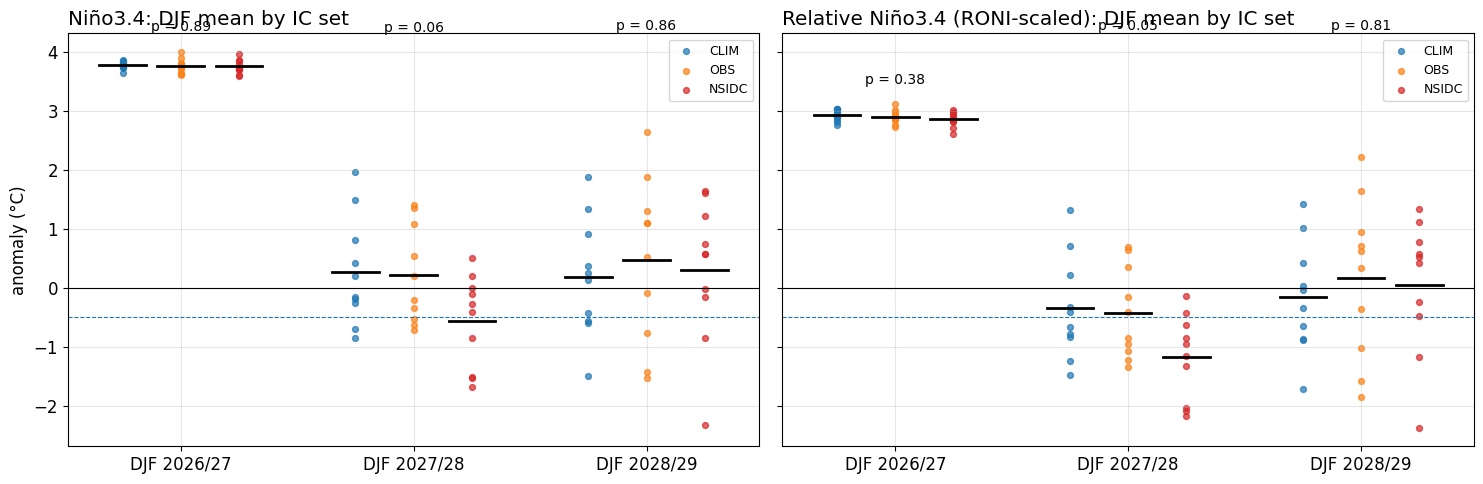

,index,winter,mean CLIM,mean OBS,mean NSIDC,sd CLIM,sd OBS,sd NSIDC,F,p (F),Levene W,p (Levene)
0,Nino3.4,2026/27,3.78,3.76,3.75,0.06,0.12,0.12,0.12,0.890,1.46,0.249
1,Nino3.4,2027/28,0.28,0.21,-0.56,0.92,0.83,0.78,3.07,0.063,0.07,0.931
2,Nino3.4,2028/29,0.18,0.47,0.30,1.01,1.40,1.21,0.15,0.862,0.60,0.555
3,Relative,2026/27,2.93,2.90,2.86,0.10,0.11,0.12,1.00,0.382,0.03,0.974
4,Relative,2027/28,-0.35,-0.43,-1.18,0.87,0.78,0.72,3.34,0.051,0.09,0.915
5,Relative,2028/29,-0.16,0.17,0.05,0.94,1.35,1.14,0.21,0.809,0.51,0.604


In [4]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, kind in zip(axes, ANOM):
    for k, (w, first) in enumerate(WINTERS.items()):
        v = ANOM[kind][:, first:first + 3].mean(1)
        groups = [v[SETS == s] for s in dict.fromkeys(SETS)]
        F, p = stats.f_oneway(*groups)
        W, pl = stats.levene(*groups)
        rows.append({"index": kind, "winter": w, **{f"mean {s}": round(g.mean(), 2) for s, g in zip(dict.fromkeys(SETS), groups)},
                     **{f"sd {s}": round(g.std(ddof=1), 2) for s, g in zip(dict.fromkeys(SETS), groups)},
                     "F": round(F, 2), "p (F)": round(p, 3), "Levene W": round(W, 2), "p (Levene)": round(pl, 3)})
        for j, (s, g) in enumerate(zip(dict.fromkeys(SETS), groups)):
            xx = k + (j - 1) * 0.25
            ax.scatter(np.full(g.size, xx), g, s=18, color=["tab:blue", "tab:orange", "tab:red"][j], alpha=0.7,
                       label=s if k == 0 else None)
            ax.plot([xx - 0.1, xx + 0.1], [g.mean()] * 2, color="k", lw=2)
        ax.text(k, ax.get_ylim()[1] if k else v.max() + 0.3, f"p = {p:.2f}", ha="center", va="bottom", fontsize=10)
    ax.set_xticks(range(len(WINTERS)), [f"DJF {w}" for w in WINTERS])
    ax.axhline(0, color="k", lw=0.8)
    ax.axhline(-0.5, color="tab:blue", ls="--", lw=0.8)
    ax.set_title(f"{'Niño3.4' if kind == 'Nino3.4' else 'Relative Niño3.4 (RONI-scaled)'}: DJF mean by IC set", loc="left")
    ax.legend(fontsize=9)
axes[0].set_ylabel("anomaly (°C)")
fig.tight_layout()
save(fig, "nov2026", "ic_set_consistency")
plt.show()
ftab = pd.DataFrame(rows)
ftab.to_csv(DATA_DIR / "ic_set_ftest.csv", index=False)
display(ftab)

### 2. Hindcast skill of the 1 Nov starts

Anomaly correlation over the Reanalysis start years of the ensemble-mean DJF Niño3.4 with HadISST, for the
first (leads 1-3) and second (leads 13-15) winter; "detrended" removes a linear trend over the years from
both. Persistence: the observed October anomaly (the month before the start) correlated with the observed DJF.
Intervals: 95% bootstrap over years. There are no 36-month hindcasts, so year 3 has no skill estimate.

In [5]:
def acc(x, y, detrend=False, n_boot=2000, seed=0):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if detrend:
        t = np.arange(x.size)
        x, y = x - np.polyval(np.polyfit(t, x, 1), t), y - np.polyval(np.polyfit(t, y, 1), t)
    r = np.corrcoef(x, y)[0, 1]
    rng = np.random.default_rng(seed)
    bs = [np.corrcoef(x[i], y[i])[0, 1] for i in (rng.integers(0, x.size, x.size) for _ in range(n_boot))]
    return r, *np.percentile(bs, [2.5, 97.5])


rows = []
for kind in ("Nino3.4", "Relative"):
    ref, _, obs = series(kind)
    oanom = obs - month_clim(obs, CLIM).reindex(obs.index.month).values
    for period in ((1981, 2018), (1981, 2010)):
        years = [y for y in ref["year"].values if period[0] <= y <= period[1]]
        for w, first in (("year 1 (DJF, leads 1-3)", 1), ("year 2 (DJF, leads 13-15)", 13)):
            fc = [float(ref.sel(year=y, lead=slice(first, first + 2)).mean()) for y in years]
            ob = [float(np.mean([oanom[target(y, L)] for L in range(first, first + 3)])) for y in years]
            pers = [oanom[target(y, -1)] for y in years]
            for detrend in (False, True):
                r, lo, hi = acc(fc, ob, detrend)
                rp, *_ = acc(pers, ob, detrend)
                rows.append({"index": kind, "starts": f"{period[0]}-{period[1]} ({len(years)})", "winter": w,
                             "detrended": detrend, "ACC": round(r, 2), "95% CI": f"{lo:.2f} to {hi:.2f}",
                             "persistence": round(rp, 2)})
skill = pd.DataFrame(rows)
skill.to_csv(DATA_DIR / "hindcast_djf_acc.csv", index=False)
display(skill)

,index,starts,winter,detrended,ACC,95% CI,persistence
0,Nino3.4,1981-2018 (38),"year 1 (DJF, leads 1-3)",False,0.95,0.90 to 0.97,0.95
1,Nino3.4,1981-2018 (38),"year 1 (DJF, leads 1-3)",True,0.97,0.94 to 0.98,0.95
2,Nino3.4,1981-2018 (38),"year 2 (DJF, leads 13-15)",False,0.47,0.16 to 0.71,-0.07
3,Nino3.4,1981-2018 (38),"year 2 (DJF, leads 13-15)",True,0.57,0.27 to 0.77,-0.07
4,Nino3.4,1981-2010 (30),"year 1 (DJF, leads 1-3)",False,0.94,0.89 to 0.97,0.95
5,Nino3.4,1981-2010 (30),"year 1 (DJF, leads 1-3)",True,0.96,0.93 to 0.98,0.95
6,Nino3.4,1981-2010 (30),"year 2 (DJF, leads 13-15)",False,0.54,0.23 to 0.75,-0.12
7,Nino3.4,1981-2010 (30),"year 2 (DJF, leads 13-15)",True,0.62,0.33 to 0.82,-0.14
8,Relative,1981-2018 (38),"year 1 (DJF, leads 1-3)",False,0.95,0.91 to 0.97,0.94
9,Relative,1981-2018 (38),"year 1 (DJF, leads 1-3)",True,0.96,0.93 to 0.98,0.94


### 3. Peak timing of the 1 Nov 2026 forecast

Peak month and the first months after it when the ensemble mean (3-month running mean, ONI-like)
falls below 0 and −0.5 °C, with the member spread; against the 2026 observations so far, the observed
strong El Niños (1981-2010 anomalies, same smoothing) and the other 2026 starts (pooled ensemble means,
rc.hindcast_anomaly).

,series,peak,peak (°C),below 0,below -0.5
0,"E3SM 1 Nov 2026, ensemble mean",2026-12,3.81,2027-10,None
1,"E3SM 1 Nov 2026, members (10-90%)",2026-11 to 2027-01,,2027-07 to 2029-05,2027-08 to 2029-07
2,"E3SM 1 Feb 2026, ensemble mean",2027-01,2.0,None,None
3,"E3SM 1 May 2026, ensemble mean",2026-12,3.71,None,None
4,"E3SM 1 Aug 2026, ensemble mean",2026-11,4.56,None,None
5,observed 1982/83 (HadISST),1983-01,2.35,1983-08,1983-09
6,observed 1997/98 (HadISST),1997-12,2.41,1998-06,1998-07
7,observed 2015/16 (HadISST),2015-12,2.58,2016-07,2016-09
8,observed 2023/24 (HadISST),2023-12,1.85,2024-09,2025-01
9,observed 2026 so far (HadISST),not yet (last 2026-09: +2.66 °C),,,


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/nov2026_outlook/02_outlook_checks/figures/fig_nov2026_peak_timing.png


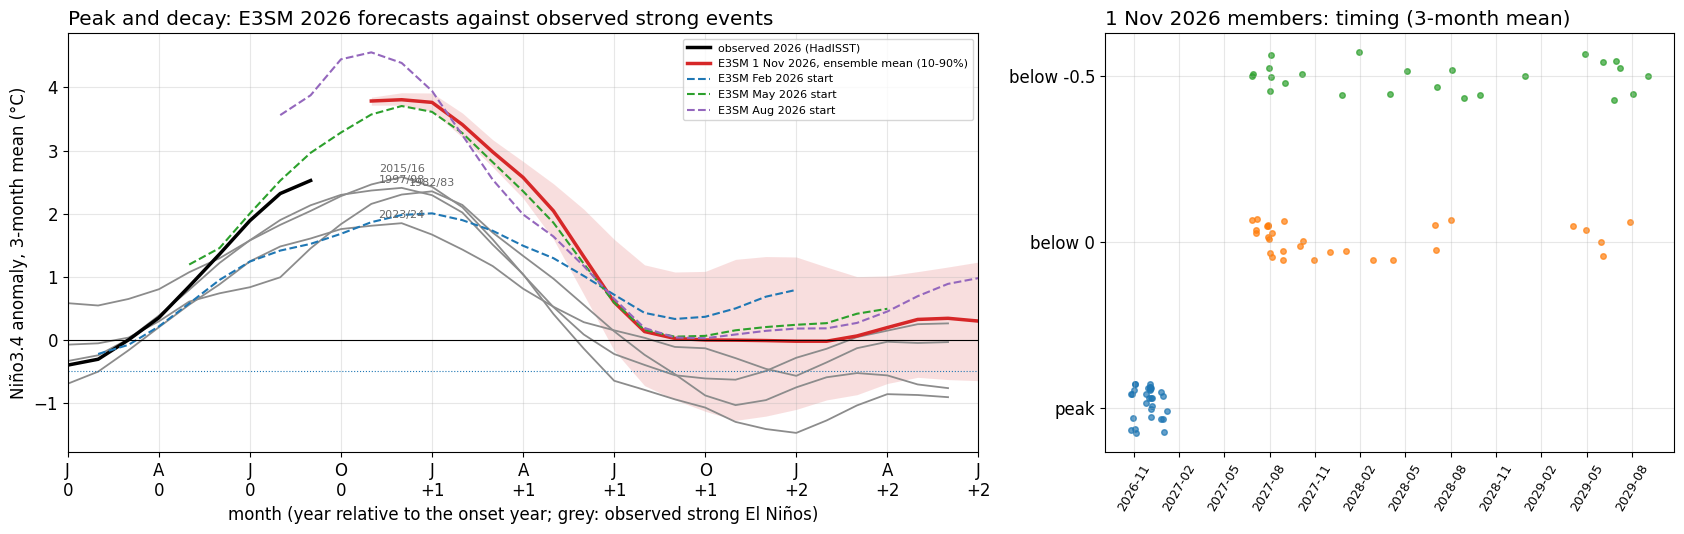

In [6]:
def timing(values, months):
    # (peak month, first month below 0, below -0.5 after the peak) of a smoothed monthly series
    s = pd.Series(values, index=months).rolling(SMOOTH, center=True, min_periods=1).mean()
    k = int(np.argmax(s.values))
    after = s.iloc[k:]
    below = lambda thr: after.index[np.argmax(after.values < thr)] if (after.values < thr).any() else None
    return s.index[k], round(float(s.iloc[k]), 2), below(0.0), below(-0.5), s


fc_months = [target(YEAR, L) for L in range(NLEAD)]
rows, member_rows = [], []
em = ANOM["Nino3.4"].mean(0)
pk, pv, z0, z5, s_em = timing(em, fc_months)
rows.append({"series": "E3SM 1 Nov 2026, ensemble mean", "peak": str(pk), "peak (°C)": pv, "below 0": str(z0), "below -0.5": str(z5)})
for m, a in zip(D["member"].values, ANOM["Nino3.4"]):
    p_, v_, z0_, z5_, _ = timing(a, fc_months)
    member_rows.append({"member": m, "peak": p_, "peak (°C)": v_, "below 0": z0_, "below -0.5": z5_})
mem = pd.DataFrame(member_rows)
lag = lambda col: [(x - pd.Period(year=YEAR, month=INIT, freq="M")).n if pd.notna(x) else np.nan for x in mem[col]]
mem["peak lead"], mem["lead below 0"], mem["lead below -0.5"] = lag("peak"), lag("below 0"), lag("below -0.5")
q = lambda c: f"{pd.Period(year=YEAR, month=INIT, freq='M') + int(np.nanpercentile(mem[c], 10))} to " \
              f"{pd.Period(year=YEAR, month=INIT, freq='M') + int(np.nanpercentile(mem[c], 90))}"
rows.append({"series": "E3SM 1 Nov 2026, members (10-90%)", "peak": q("peak lead"), "peak (°C)": "",
             "below 0": q("lead below 0"), "below -0.5": q("lead below -0.5")})

# other 2026 starts (pooled ensemble means, 24 leads)
other = {}
for init in OTHER_STARTS:
    arrs = []
    for prefix in POOL.values():
        a = rc.hindcast_anomaly(prefix, init, "TS", year=YEAR, mode=derivation_mode)
        if a is not None:
            arrs.append(rc.box_mean(a, NINO_BOX).load())
    n34 = xr.concat(arrs, "member").mean(["member"] + [d for d in arrs[0].dims if d not in ("member", "lead")])
    months = [pd.Period(year=YEAR, month=init, freq="M") + L for L in range(n34.sizes["lead"])]
    pk_, pv_, z0_, z5_, s_ = timing(n34.values, months)
    other[init] = s_
    rows.append({"series": f"E3SM 1 {['', 'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug'][init]} 2026, ensemble mean",
                 "peak": str(pk_), "peak (°C)": pv_, "below 0": str(z0_), "below -0.5": str(z5_)})

# observations
oanom = OBS - month_clim(OBS, CLIM).reindex(OBS.index.month).values
obs_events = {}
for y in STRONG_EVENTS:
    seg = oanom[(oanom.index >= pd.Period(year=y, month=1, freq="M")) & (oanom.index <= pd.Period(year=y + 2, month=6, freq="M"))]
    if seg.empty:
        continue
    pk_, pv_, z0_, z5_, s_ = timing(seg.values, list(seg.index))
    obs_events[y] = s_
    rows.append({"series": f"observed {y}/{str(y + 1)[2:]} (HadISST)", "peak": str(pk_), "peak (°C)": pv_,
                 "below 0": str(z0_), "below -0.5": str(z5_)})
obs26 = oanom[oanom.index >= pd.Period(year=YEAR, month=1, freq="M")]
rows.append({"series": "observed 2026 so far (HadISST)", "peak": f"not yet (last {obs26.index[-1]}: {obs26.iloc[-1]:+.2f} °C)",
             "peak (°C)": "", "below 0": "", "below -0.5": ""})
tim = pd.DataFrame(rows)
tim.to_csv(DATA_DIR / "peak_timing.csv", index=False)
mem.to_csv(DATA_DIR / "peak_timing_members.csv", index=False)
display(tim)

# figure: event-relative composite (months from 1 Jan of the onset year)
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
rel = lambda idx, y0: [(p - pd.Period(year=y0, month=1, freq="M")).n for p in idx]
for y, s in obs_events.items():
    ax.plot(rel(s.index, y), s.values, color="0.55", lw=1.3)
    ax.text(rel(s.index, y)[int(np.argmax(s.values))], s.max() + 0.08, f"{y}/{str(y + 1)[2:]}", fontsize=8, color="0.4", ha="center")
s_obs = obs26.rolling(SMOOTH, center=True, min_periods=1).mean()
ax.plot(rel(s_obs.index, YEAR), s_obs.values, color="k", lw=2.5, label="observed 2026 (HadISST)")
lo, hi = np.percentile(ANOM["Nino3.4"], [10, 90], axis=0)
xs = rel(fc_months, YEAR)
ax.fill_between(xs, pd.Series(lo).rolling(SMOOTH, center=True, min_periods=1).mean(),
                pd.Series(hi).rolling(SMOOTH, center=True, min_periods=1).mean(), color="tab:red", alpha=0.15, lw=0)
ax.plot(xs, s_em.values, color="tab:red", lw=2.5, label="E3SM 1 Nov 2026, ensemble mean (10-90%)")
for init, c in zip(OTHER_STARTS, ["tab:blue", "tab:green", "tab:purple"]):
    s = other[init]
    ax.plot(rel(s.index, YEAR), s.values, color=c, lw=1.5, ls="--", label=f"E3SM {['', '', 'Feb', '', '', 'May', '', '', 'Aug'][init]} 2026 start")
ax.axhline(0, color="k", lw=0.8)
ax.axhline(-0.5, color="tab:blue", ls=":", lw=0.8)
ax.set_xticks(range(0, 31, 3), [f"{'JFMAMJJASOND'[m % 12]}\n{'+' + str(m // 12) if m >= 12 else '0'}" for m in range(0, 31, 3)])
ax.set_xlim(0, 30)
ax.set_xlabel("month (year relative to the onset year; grey: observed strong El Niños)")
ax.set_ylabel("Niño3.4 anomaly, 3-month mean (°C)")
ax.set_title("Peak and decay: E3SM 2026 forecasts against observed strong events", loc="left")
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
for j, (col, lab) in enumerate([("peak lead", "peak"), ("lead below 0", "below 0"), ("lead below -0.5", "below -0.5")]):
    vals = mem[col].dropna().values
    ax.scatter(vals + np.random.default_rng(j).uniform(-0.2, 0.2, vals.size), np.full(vals.size, j) + np.random.default_rng(j + 9).uniform(-0.15, 0.15, vals.size),
               s=16, alpha=0.7)
ax.set_yticks(range(3), ["peak", "below 0", "below -0.5"])
ticks = range(0, NLEAD, 3)
ax.set_xticks(list(ticks), [str(pd.Period(year=YEAR, month=INIT, freq="M") + t) for t in ticks], rotation=60, fontsize=9)
ax.set_title("1 Nov 2026 members: timing (3-month mean)", loc="left")
fig.tight_layout()
save(fig, "nov2026", "peak_timing")
plt.show()

### Findings

**1. Pooling is justified.** No winter shows a significant difference between the clim, obs and NSIDC sets
(F-test p = 0.89, 0.06, 0.86 for DJF 2026/27, 2027/28, 2028/29 in Niño3.4; 0.38, 0.05, 0.81 for the relative
index), and their spreads are indistinguishable (Levene p ≥ 0.25). The one borderline case is DJF 2027/28,
where the NSIDC set is colder (Niño3.4 −0.56 °C against +0.28 and +0.21 for clim and obs): the NSIDC sea ice
may push the second winter toward La Niña, which 10 members per set cannot confirm or rule out.

**2. Hindcast skill of the 1 Nov starts** (Reanalysis ensemble mean against HadISST, 1981-2018):

| Niño3.4 DJF | ACC (95% CI) | detrended | persistence of Oct |
|---|---|---|---|
| year 1 (leads 1-3) | 0.95 (0.90-0.97) | 0.97 | 0.95 |
| year 2 (leads 13-15) | 0.47 (0.16-0.71) | 0.57 | −0.07 |

The first winter is as predictable as persistence (a 1 Nov start sees the event under way). The second winter
keeps real skill where persistence has none, so the DJF 2027/28 outlook is informative. No 36-month
hindcasts exist, so DJF 2028/29 has no skill estimate; with the year-2 correlation already near 0.5 it should
be presented as low-confidence. The relative index scores the same (0.95; 0.48).

**3. Peak timing.** The 1 Nov 2026 ensemble mean (3-month means) peaks in **Dec 2026** (members: Nov 2026 to
Jan 2027), the same months as the observed strong events (Dec 1997, Dec 2015, Dec 2023, Jan 1983), and the
Feb/May/Aug starts peak between Nov 2026 and Jan 2027 as well. E3SM does not peak late; it **decays late**: its
ensemble mean crosses zero in **Oct 2027**, against Jun-Sep of the year after the peak in the observed strong
events (1983-08, 1998-06, 2016-07, 2024-09), i.e. 1-4 months later, with members from Jul 2027 to 2029. The
peak is also large (3.8 °C against 1.9-2.6 °C for the observed events; the observed 2026 value was already
+2.7 °C in Sep). A slow decay delays the transition to La Niña, which is consistent with the low
P(La Niña 2027/28) under the 1981-2010 drift (`01_year3_drift_sensitivity`).